In [10]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'   # ajuste para o nº de núcleos do seu computador

# 05 — Modelagem (Fase 4): regressão logística

Este notebook leva o projeto da exploração (Fase 3) para a **previsão**: dado o balanço de uma empresa **fora de distress em t**, qual a chance de ela entrar em distress em t+1 e t+2? A regressão logística é o modelo principal, comparada com a baseline (Z'' de Altman) e com um desafiante não linear.

Regras que vêm dos notebooks anteriores e valem aqui:
- **O teste (t = 2021–2023) só é aberto na seção 7, uma vez**, depois de congelar modelo, variáveis, hiperparâmetros e limiar. Nada antes dela olha o teste.
- **Hiperparâmetros por validação temporal expandida dentro do treino** (notebook 04, "Riscos da escolha B"), com intervalo de 2 anos entre treino e validação, porque o alvo de t olha t+1 e t+2.
- **Nada que aprende dos dados é calculado fora do pipeline**: limites da winsorização, p99 do sem-dívida, medianas, média e desvio da padronização e coeficientes são ajustados só no treino de cada dobra (`src/modelagem.py`). Por isso aqui usamos as colunas cruas, e não as `*_w` da Fase 2.
- **Métrica principal: AUC-PR**, com AUC-ROC, Brier e recall no top 20% como apoio. Acurácia não entra: prever sempre "não" já acerta cerca de 90%.
- **Incerteza honesta**: os intervalos vêm de *bootstrap por empresa* (a mesma empresa aparece em vários anos), e a validação tem poucos eventos.

| decisão | valor aplicado aqui | situação |
|---|---|---|
| definição do alvo | `cfg.ALVO_MODELO` (B: EBITDA / desp. fin. < 1 em t+1 e t+2) | recomendação do notebook 04; **a escolha é da dupla** |
| empresas sem dívida | `fco_divida` = p99 do treino, `divida_cp_share` = 0, flag `sem_divida` | sugestão do notebook 03; **pendente** (comparada na seção 6) |
| controle de tempo | nenhum (risco relativo dentro de cada ano) | **pendente** (Selic/PIB: ver `cfg.MACRO_COLS`) |
| setor | macrossetor provisório da CVM | pendente: Subsetor Bovespa |
| divisão | treino 2010–2018, validação 2019–2020, teste 2021–2023 | decidida em 21/10/2026 |

Os **títulos dos gráficos estão neutros** de propósito: depois de ler o resultado, troque-os pela afirmação que ele sustenta (como nos notebooks 03 e 04).

In [11]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, modelagem as mod, avaliacao as av, style

style.aplicar()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: style.num_br(x, 3))

ea = mod.carregar_base()
amostra = mod.preparar_amostra(ea)   # alvo cfg.ALVO_MODELO; amostra em risco, t de 2010 a 2023
print(f'Alvo {cfg.ALVO_MODELO}:', cfg.DEFINICOES_ALVO[cfg.ALVO_MODELO], '| base:', ea.shape, '| amostra em risco:', len(amostra))

Alvo B: ('ebitda', 2) | base: (3633, 58) | amostra em risco: 1845


## 1. Amostra e divisão temporal

A amostra é a mesma do notebook 04 para a definição escolhida: empresas **fora de distress em t** (pela mesma definição), com Y observado, sem anos anteriores ao registro na CVM e com t até 2023.

O critério 3 do notebook 04 (idealmente 10 eventos por parâmetro) não é atingido por nenhuma definição, e a B fica em cerca de 6. Por isso a logística usa **regularização L2** (seção 3).

In [12]:
resumo = mod.resumo_amostra(amostra)
esperado = {'A': (115, 17, 52), 'B': (82, 11, 31)}   # eventos treino / validação / teste, notebook 04, seção 4
obtido = tuple(int(resumo.loc[s, 'eventos']) for s in ['treino', 'validacao', 'teste'])
print('eventos (treino, validação, teste):', obtido, '| notebook 04:', esperado.get(cfg.ALVO_MODELO), '(devem bater)')
resumo.style.format({'n': lambda x: style.num_br(x, 0), 'eventos': lambda x: style.num_br(x, 0), 'empresas': lambda x: style.num_br(x, 0),
                     'taxa': lambda x: style.pct_br(x, 1), 'eventos por parâmetro': lambda x: style.num_br(x, 1)}, na_rep='')

eventos (treino, validação, teste): (82, 11, 31) | notebook 04: (82, 11, 31) (devem bater)


,n,eventos,taxa,empresas,eventos por parâmetro
treino,1.013,82,"8,1%",175,"6,3"
validacao,286,11,"3,8%",168,
teste,546,31,"5,7%",214,
total,1.845,124,"6,7%",243,


**Leitura** *(a preencher)*. O que olhar: (i) os eventos batem com o notebook 04?; (ii) quantos eventos a **validação** tem? Com poucas dezenas ou menos, qualquer métrica nela é instável, e por isso ela **não escolhe nada** aqui: serve só de conferência; (iii) a taxa de eventos varia entre treino, validação e teste?

## 2. Pré-processamento (dentro do pipeline)

Cada modelo é um `Pipeline` do scikit-learn com estas etapas, todas ajustadas **só no treino da dobra**:

1. **Winsorização** nos percentis 1% e 99% (mesma regra da Fase 2, `base.limites_winsor`), das seis explicativas contínuas;
2. **Regra do sem-dívida** (`cfg.REGRA_SEM_DIVIDA`): `fco_divida` recebe o teto do treino e `divida_cp_share`, 0; a flag `sem_divida` fica no modelo;
3. **Imputação pela mediana** do que ainda faltar e **padronização** (média 0, desvio 1): os coeficientes ficam por +1 desvio-padrão e a penalidade L2 trata todas as variáveis igualmente;
4. **Dummies de macrossetor**.

Não há dummies de ano: elas não existem para os anos do teste. O ciclo econômico, que o notebook 03 mostrou pesar muito (taxa de 3% a 28% por ano), fica fora do modelo, que então mede risco **relativo** entre empresas.

In [13]:
treino = amostra[amostra['split'] == 'treino'].reset_index(drop=True)
validacao = amostra[amostra['split'] == 'validacao'].reset_index(drop=True)

prep = mod.preprocessador().fit(treino[mod.colunas_entrada()], treino['Y'])
lim = pd.DataFrame(prep['winsor'].limites_, index=['p1', 'p99']).T
print('Teto de fco_divida usado para as empresas sem dívida:', style.num_br(prep['sem_divida'].teto_fco_, 2))
lim

Teto de fco_divida usado para as empresas sem dívida: 7,43


,p1,p99
alavancagem,"0,000","0,705"
divida_cp_share,"0,022","0,987"
roa,"-0,021","0,241"
liquidez,"0,005","5,810"
fco_divida,"-0,520","7,428"
log_ativo,"10,922","19,543"


In [14]:
# O que o modelo enxerga no treino: média 0 e desvio 1 nas contínuas; flag e dummies em 0/1
prep.transform(treino[mod.colunas_entrada()]).describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
alavancagem,"-0,000","1,000","-1,802","2,475"
divida_cp_share,"0,000","1,000","-1,382","3,066"
roa,"0,000","1,000","-1,628","3,563"
liquidez,"0,000","1,000","-0,670","7,045"
fco_divida,"-0,000","1,000","-0,761","3,879"
log_ativo,"-0,000","1,000","-2,524","2,698"
sem_divida,"0,037","0,188","0,000","1,000"
setor_Bens industriais,"0,160","0,367","0,000","1,000"
setor_Comunicações e TI,"0,044","0,206","0,000","1,000"
setor_Construção e imobiliário,"0,158","0,365","0,000","1,000"


## 3. Escolha de C por validação temporal expandida

`C` é o inverso da regularização L2: quanto **menor**, mais os coeficientes são encolhidos em direção a zero, o que protege contra o excesso de parâmetros para poucos eventos.

Cada dobra valida em **um ano** do treino (2015–2018) e treina com os anos até `v − 3`. O intervalo de 2 anos existe porque o rótulo de t usa t+1 e t+2: com ele, nenhum rótulo de treino usa informação do ano de validação. Dobras com poucos eventos no treino (`cfg.MIN_EVENTOS_DOBRA`) são descartadas.

Escolha de `C` (`cfg.REGRA_C`): por padrão, o `C` de **maior AUC-PR** fora da amostra (`'max'`). A alternativa `'1ep'` é a regra clássica de parcimônia (o `C` mais regularizado a até 1 erro-padrão do melhor, com erro-padrão por *bootstrap por empresa*), mas **cuidado**: AUC-PR e AUC-ROC só olham o ranking, e encolher os coeficientes quase não piora o ranking. A curva fica plana e a regra de 1 EP tende a escorregar para a ponta mais regularizada da grade, que é um modelo quase nulo. Use-a só se a curva tiver um formato claro.

In [15]:
dobras, descartadas = mod.dobras_temporais(treino)
pd.DataFrame([{'ano de validação': v, 'treino: t até': treino.loc[tr, 'ano'].max(), 'n treino': len(tr),
               'eventos treino': int(treino.loc[tr, 'Y'].sum()), 'n validação': len(va),
               'eventos validação': int(treino.loc[va, 'Y'].sum())} for tr, va, v in dobras])
if descartadas:
    print('Dobras descartadas (ano, eventos no treino, eventos na validação):', descartadas)

In [16]:
res = mod.ajuste_completo(amostra)   # logística L2, pesos balanceados, setor, regra p99/0
tabC = res['tabela_C']
print(f"C escolhido: {res['C']} | regra: {cfg.REGRA_C} | erro-padrão da AUC-PR: {style.num_br(tabC.attrs['ep'], 3)} | "
      f"limiar (F{cfg.BETA_LIMIAR:g}, previsões fora da amostra): {style.num_br(res['limiar'], 3)}")
tabC

C escolhido: 1.0 | regra: max | erro-padrão da AUC-PR: 0,069 | limiar (F2, previsões fora da amostra): 0,598


,C,AUC-PR,AUC-ROC,Brier,AUC-PR por dobra (média),melhor,escolhido
0,"0,001","0,120","0,680","0,241","0,176",False,False
1,"0,003","0,126","0,677","0,231","0,173",False,False
2,"0,010","0,135","0,677","0,221","0,174",False,False
3,"0,030","0,150","0,681","0,218","0,178",False,False
4,"0,100","0,177","0,681","0,218","0,170",False,False
5,"0,300","0,185","0,673","0,220","0,172",False,False
6,"1,000","0,190","0,659","0,222","0,171",True,True
7,"3,000","0,187","0,653","0,222","0,166",False,False
8,"10,000","0,186","0,652","0,220","0,163",False,False


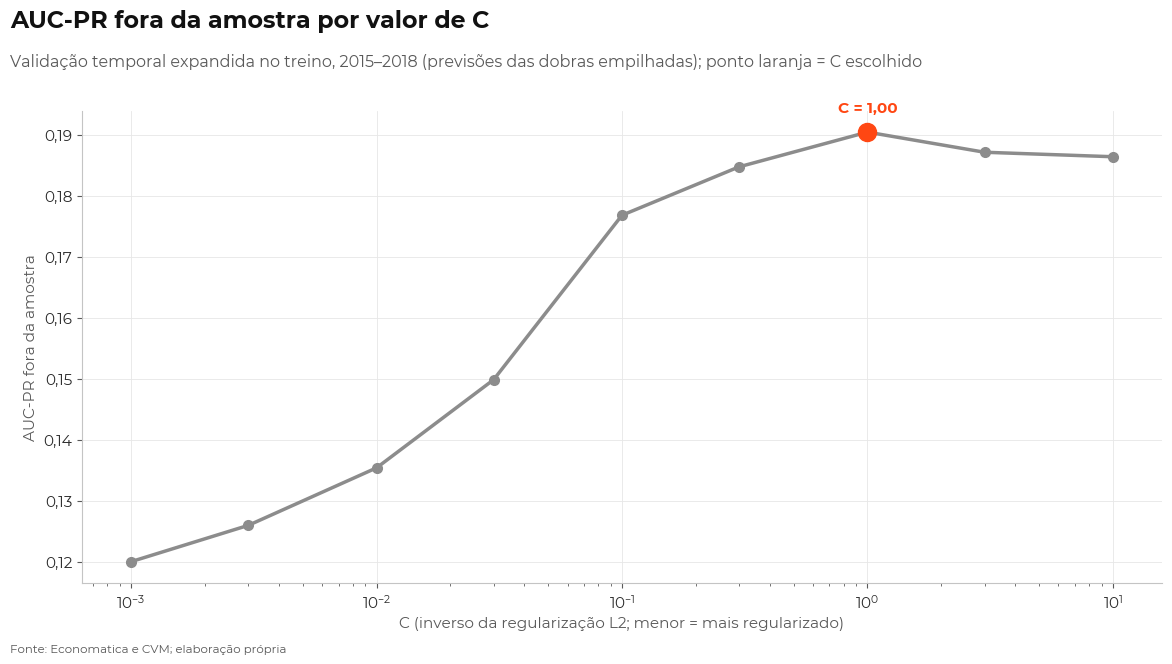

In [17]:
fig, ax = av.fig_selecao_c(tabC, res['C'])
style.titulos(fig, 'AUC-PR fora da amostra por valor de C',
              'Validação temporal expandida no treino, 2015–2018 (previsões das dobras empilhadas); ponto laranja = C escolhido')
style.salvar(fig, 'fig17_selecao_c')
plt.show()

**Leitura** *(a preencher)*. O que olhar: (i) o `C` escolhido está na **borda** da grade? Se sim, o código avisa; estenda `cfg.GRADE_C` nessa direção; (ii) a curva é plana (diferenças menores que o erro-padrão, que aparece acima)? Então a regularização importa pouco e a escolha de `C` não deve pesar na conclusão; (iii) a AUC-PR fora da amostra está acima da taxa de eventos (a de um modelo sem informação)?

## 4. Modelos na validação (2019–2020)

Comparamos, ajustados no treino:
- **Z'' (baseline)**: o Z''-score de Altman para emergentes, recalibrado por uma logística de uma variável. A ordenação (AUC-PR e AUC-ROC) é a do próprio Z'';
- **Logística L2 com pesos de classe balanceados** (modelo principal): melhora o recall, mas **infla as probabilidades**;
- **Logística L2 sem pesos**: probabilidades calibradas, importantes para o Brier;
- **Logística com splines** em alavancagem e tamanho (o notebook 03 viu limiar na alavancagem e U no tamanho);
- **Gradient boosting raso** (desafiante não linear, hiperparâmetros fixos).

O **limiar** de cada modelo maximiza o F2 (privilegia o recall) nas previsões fora da amostra das dobras do treino. A validação **não** é usada para escolher nada.

> **Brier:** só compare entre modelos calibrados (Z'' e logística sem pesos). Com `class_weight='balanced'` as probabilidades saem infladas por construção, e o Brier piora sem que o ranking piore.

In [20]:
res_sp = mod.ajuste_completo(amostra, class_weight=None)
res_spl = mod.ajuste_completo(amostra, splines=True)
z = mod.ajuste_fixo(mod.pipeline_z, treino, dobras)
gb = mod.ajuste_fixo(mod.pipeline_gb, treino, dobras)

modelos = {"Z'' (baseline)": z,
           'Logística L2 (pesos balanceados)': res,
           'Logística L2 (sem pesos)': res_sp,
           'Logística com splines': res_spl,
           'Gradient boosting (desafiante)': gb}
PRINCIPAL = 'Logística L2 (pesos balanceados)'
limiares = {k: v['limiar'] for k, v in modelos.items()}

prev_val = {k: mod.prever(v['modelo'], validacao) for k, v in modelos.items()}
av.tabela_metricas(validacao['Y'], prev_val, limiares)

c:\Users\davif\OneDrive - Insper - Instituto de Ensino e Pesquisa\Área de Trabalho\Insper\Insper Data\Projeto-2_CB\src\modelagem.py:252: UserWarning: C escolhido (10.0) está na borda da grade: estenda cfg.GRADE_C nessa direção.
  warnings.warn(f'C escolhido ({c_esc}) está na borda da grade: estenda cfg.GRADE_C nessa direção.')


,n,eventos,taxa,AUC-PR,AUC-ROC,Brier,recall top 20%,limiar,marcados,precisão,recall,F2
Z'' (baseline),"286,000","11,000","0,038","0,108","0,650","0,039","0,455","0,047","278,000","0,040","1,000","0,171"
Logística L2 (pesos balanceados),"286,000","11,000","0,038","0,057","0,644","0,211","0,364","0,598","59,000","0,068","0,364","0,194"
Logística L2 (sem pesos),"286,000","11,000","0,038","0,061","0,634","0,040","0,364","0,077","96,000","0,052","0,455","0,179"
Logística com splines,"286,000","11,000","0,038","0,052","0,600","0,201","0,091","0,632","45,000","0,022","0,091","0,056"
Gradient boosting (desafiante),"286,000","11,000","0,038","0,077","0,705","0,121","0,273","0,102","186,000","0,054","0,909","0,217"


**Leitura** *(a preencher)*. O que olhar: a logística supera o Z'' em AUC-PR e AUC-ROC? Lembre que a validação tem poucos eventos, então diferenças pequenas **não** são evidência. A tabela serve para detectar problemas (modelo pior que o acaso, limiar absurdo), e não para eleger o vencedor.

## 5. Inferência: as hipóteses H1–H4 (treino)

O estudo é de **associação**. Para testar as hipóteses ajustamos a logística **sem penalização** no treino, com **erro-padrão robusto agrupado por empresa** (o painel repete a mesma empresa em vários anos, então o erro-padrão comum seria otimista). Intervalos de 90%.

Como ler:
- razão de chances **por +1 desvio-padrão** da variável (winsorizada), controlando pelas demais e pelo setor;
- **confirma** = sinal esperado e p < 0,10. "Sinal certo, não significativo" **não** é confirmação;
- para a inferência usamos `regra='nenhuma'` (mediana) no sem-dívida: com uma constante mais a flag, o ajuste é o mesmo, mas só a mediana deixa o coeficiente de `sem_divida` legível ("sem dívida" contra uma empresa com dívida típica). Com o p99, a razão de chances da flag só desfaz o valor imputado e perde o sentido;
- coeficientes provavelmente **atenuados** pelo viés de sobrevivência (README).

In [19]:
Xi = mod.matriz_inferencia(treino)
coefs = mod.logit_agrupado(Xi, treino['Y'], treino['ticker'])
print(f"N = {coefs.attrs['N']} empresa-anos | {coefs.attrs['empresas']} empresas (clusters) | setor de referência: {Xi.attrs['setor_referencia']}")
hip = mod.tabela_hipoteses(coefs)
hip[['hipótese', 'sinal esperado', 'sinal estimado', 'odds_ratio', 'or_inf', 'or_sup', 'p', 'veredito']]

RuntimeError: A logística sem penalização não convergiu (separação perfeita). Colunas sem variação no alvo quando = 1: ['setor_Sem classificação']. Junte categorias de setor ou retire a flag.

In [ ]:
fig, ax = av.fig_coeficientes(hip)
style.titulos(fig, 'Razão de chances de entrar em distress por +1 desvio-padrão de cada indicador',
              'Logística sem penalização no treino 2010–2018, IC de 90% com erro-padrão agrupado por empresa · laranja = confirma a hipótese')
fig.subplots_adjust(left=0.22)
style.salvar(fig, 'fig18_coeficientes')
plt.show()
coefs   # inclui constante, flag e dummies de setor

**Leitura** *(a preencher)*. O que olhar, hipótese por hipótese: sinal, tamanho do efeito (razão de chances) e se o intervalo cruza 1. Compare com o notebook 03 (bivariado): o ROA e o FCO/dívida continuam fortes **controlando pelas demais**? A alavancagem, que tinha cara de limiar, aparece com efeito linear fraco (e então os splines da seção 4 importam)? A dívida de curto prazo, sem padrão bivariado, ganha algum efeito controlada?

## 6. Decisões pendentes: o que os dados dizem

Cada linha refaz **todo** o pipeline (escolha de C no treino incluída) com uma variante das decisões em aberto. A comparação é pela **AUC-PR fora da amostra no treino** (validação temporal), nunca pelo teste. Se as diferenças ficam dentro do erro-padrão, os dados não distinguem as opções: escolha a mais simples ou a mais defensável.

In [ ]:
variantes = {
    'principal (p99 e 0 no sem-dívida, com setor, linear, pesos)': res,
    'sem-dívida: sem regra especial (mediana + flag)': mod.ajuste_completo(amostra, regra='nenhuma'),
    'sem controle de setor': mod.ajuste_completo(amostra, usar_setor=False),
    'com splines em alavancagem e tamanho': res_spl,
    'sem pesos de classe': res_sp,
}
linhas = []
for nome, r in variantes.items():
    t = r['tabela_C']
    e = t[t['escolhido']].iloc[0]
    linhas.append({'variante': nome, 'C': e['C'], 'AUC-PR (CV)': e['AUC-PR'], 'AUC-ROC (CV)': e['AUC-ROC'],
                   'Brier (CV)': e['Brier'], 'EP da AUC-PR': t.attrs['ep']})
pd.DataFrame(linhas).set_index('variante')

**Leitura** *(a preencher)*. Decisões a tomar com a tabela: (i) **regra do sem-dívida** (linhas 1 e 2); (ii) **vale manter o setor provisório** (linhas 1 e 3), já que ele muda quando o Subsetor Bovespa chegar?; (iii) os **splines** compensam a complexidade (linhas 1 e 4)?; (iv) pesos de classe: afetam o ranking? (o Brier não é comparável aqui, ver seção 4).

## 7. Teste (t = 2021–2023): abrir **uma vez**

Antes de rodar esta seção, o que está **congelado**: alvo (`cfg.ALVO_MODELO`), variáveis, regras de pré-processamento, `C` de cada logística (escolhido na seção 3) e limiar de cada modelo (previsões fora da amostra no treino). Se algo mudar depois de ver o teste, a avaliação deixa de ser independente: registre a mudança como análise exploratória.

O modelo é ajustado **só com o treino (2010–2018)**, e não com treino + validação. O motivo é o intervalo: o rótulo de t = 2019–2020 usa os anos 2021–2022, que são anos do teste. Treinar com eles seria usar o futuro do teste.

Intervalos de 90% por *bootstrap por empresa*; a pergunta central é se a logística supera a baseline Z'', então comparamos **diferenças** na mesma reamostragem.

In [ ]:
teste = amostra[amostra['split'] == 'teste'].reset_index(drop=True)
prev_te = {k: mod.prever(v['modelo'], teste) for k, v in modelos.items()}
av.tabela_metricas(teste['Y'], prev_te, limiares)

In [ ]:
p = prev_te[PRINCIPAL]
marcado = p >= limiares[PRINCIPAL]
cm = pd.crosstab(pd.Series(np.where(teste['Y'] == 1, 'entrou em distress', 'não entrou'), name='real'),
                 pd.Series(np.where(marcado, 'marcada como risco', 'não marcada'), name=f'{PRINCIPAL}, no limiar'))
cm

In [ ]:
resumo_boot, difs = av.bootstrap_empresas(teste['Y'], prev_te, teste['ticker'], referencia="Z'' (baseline)")
difs

In [ ]:
fig, ax = av.fig_pr(teste['Y'], prev_te, PRINCIPAL)
style.titulos(fig, 'Precisão × recall de cada modelo no teste',
              'Entrada em distress, t = 2021–2023 · legenda: AUC-PR · linha tracejada = modelo sem informação')
style.salvar(fig, 'fig19_precisao_recall_teste')
plt.show()

In [ ]:
fig, ax = av.fig_ic(resumo_boot, 'AUC-PR', destaque=PRINCIPAL, taxa=teste['Y'].mean())
style.titulos(fig, 'AUC-PR de cada modelo no teste, com intervalo de incerteza',
              'Mediana e intervalo de 90% (bootstrap por empresa, 1.000 reamostragens) · linha tracejada = modelo sem informação')
fig.subplots_adjust(left=0.27)
style.salvar(fig, 'fig20_auc_pr_ic_teste')
plt.show()
resumo_boot

In [ ]:
fig, ax = av.fig_calibracao(teste['Y'], {k: prev_te[k] for k in [PRINCIPAL, 'Logística L2 (sem pesos)', "Z'' (baseline)"]}, PRINCIPAL)
style.titulos(fig, 'Probabilidade prevista × taxa observada no teste',
              'Quintis de previsão · a diagonal é a calibração perfeita; pesos de classe inflam as probabilidades da logística principal')
style.salvar(fig, 'fig21_calibracao_teste')
plt.show()

In [ ]:
# Previsões do teste para consulta (data/processed não é versionado)
saida = teste[['ticker', 'ano', 'Y']].copy()
for k, v in prev_te.items():
    saida[k] = v
saida.to_csv(cfg.DATA_PROCESSED / 'previsoes_teste.csv', index=False)
saida.sort_values(PRINCIPAL, ascending=False).head(15)

**Leitura** *(a preencher)*. O que olhar: (i) AUC-PR da logística contra a taxa de eventos e contra o Z'' (a **diferença** e a fração `P(> Z'')` da tabela de diferenças, mais honestas que olhar as duas barras); (ii) o intervalo da AUC-PR é largo? Com poucas dezenas de eventos, deve ser; escreva isso nas conclusões; (iii) no limiar, quantos eventos o modelo captura (recall) ao custo de quantos alarmes falsos (precisão)?; (iv) calibração: a logística sem pesos fica perto da diagonal?

## 8. Robustez

Cada linha refaz o pipeline inteiro (escolha de C no treino, ajuste no treino, avaliação no teste) para uma amostra ou especificação alternativa. O que importa é se a **conclusão** (logística contra Z'') se mantém, e não o número exato. Do notebook 03 ainda falta o **painel balanceado**: depende de a dupla definir o que é balanceado aqui.

In [ ]:
rob = [mod.avaliar_cenario(amostra, f'principal (alvo {cfg.ALVO_MODELO})'),
       mod.avaliar_cenario(mod.preparar_amostra(ea, cfg.ALVO_ROBUSTEZ),
                           f'alvo {cfg.ALVO_ROBUSTEZ} ({cfg.DEFINICOES_ALVO[cfg.ALVO_ROBUSTEZ][0].upper()})'),
       mod.avaliar_cenario(amostra[~amostra['sem_divida']], 'sem as empresas sem dívida'),
       mod.avaliar_cenario(amostra, 'sem controle de setor', usar_setor=False)]
pd.DataFrame(rob).set_index('cenário')

**Leitura** *(a preencher)*. O que olhar: a logística supera o Z'' em todos os cenários? O resultado muda com o alvo A (EBIT)? Se mudar, a conclusão depende da definição do alvo e isso entra nas limitações.

## 9. Conclusões *(a preencher)*

Roteiro para quando o notebook rodar com a base real:
1. **Hipóteses** (seção 5): quais de H1–H4 se confirmam controlando pelas demais, com que tamanho de efeito.
2. **Previsão** (seção 7): a logística supera o Z''? Por quanto, com que incerteza?
3. **Uso prático**: no limiar escolhido, quantos eventos o modelo captura e a que custo em alarmes falsos.
4. **Limitações** que devem constar: viés de sobrevivência (probabilidades como risco relativo), poucos eventos (intervalos largos), setor provisório, ausência de controle de tempo, alvo baseado em cobertura de juros e **despesa financeira bruta** do Economatica.

### Decisões que continuam com a dupla
- **Alvo A ou B** (`cfg.ALVO_MODELO`).
- **Regra do sem-dívida** (seção 6).
- **Controle de tempo**: nenhum, ou Selic/PIB (crie `data/raw/macro/macro_anual.csv` e preencha `cfg.MACRO_COLS`). O notebook 04 prevê a Selic entre os 13 parâmetros, mas a base atual não a traz.
- **Beta do limiar** (`cfg.BETA_LIMIAR`, hoje 2): quanto vale um distress não detectado contra um alarme falso?
- **Painel balanceado** na robustez.
- Trocar o desafiante pelo **XGBoost** (já está no `requirements.txt`).